In [1]:
cd ..

c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines


In [2]:
# yaml processing file loading. 
import yaml
from os.path import  join

from time import time
from stl import mesh
from base.utils import array_to_o3d
from base.LBC_centreline import return_LBC_centreline


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [3]:
with open(f"./notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

In [4]:
lbc_times = []
lbc_sizes = []

In [5]:
## big loop, storing time taken to compute the LBC centrelines. 
for ID in range(1, 11):
    CONDUIT_NAME = conduit_map[ID]
    ## import the mesh data. 
    mesh_fp =  f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
    data = mesh.Mesh.from_file(mesh_fp)
    lbc_centreline_fp = join(f"./temp/{ID}_{CONDUIT_NAME}/lbc/", f"{CONDUIT_NAME}_centreline.txt")

    pcd = data.centroids
    # convert to open3d object-
    pcd = array_to_o3d(pcd)

    with open(f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
        process_p = yaml.safe_load(f)
        f.close()

    # definition of processing metaparameters
    lbc_args = dict(init_attraction = process_p["lbc"]["initAttraction"], 
                    init_contraction = process_p["lbc"]["initContraction"],
                    down_sample = process_p["lbc"]["voxelSize"])

    ct_args = dict(keep = True, keep_centreline = False, centreline_down_sample = process_p["lbc"]["downSample"])
    
    s = time()

    out_LBC = return_LBC_centreline(data,
                            ct_args= ct_args,
                            lbc_args= lbc_args)
    e= time()
    lbc_times.append(e-s)
    lbc_sizes.append(out_LBC["skeleton_cloud_size"])
    print(f"conduit {ID}: {e-s:.6f}s")

read file in 0.0000s


2026-03-25 12:20:43,269 - PCD #points: 2000


contracted file in 0.3232s


Volume ratio: 1.0. Contraction weights: 354.0875757639706. Attraction weights: 4.278736902212761. Progress LBC:  15%|█▌        | 3/20 [00:00<00:02,  6.54it/s]2026-03-25 12:20:43,936 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 354.0875757639706. Attraction weights: 4.278736902212761. Progress LBC:  15%|█▌        | 3/20 [00:00<00:03,  5.54it/s]


Contraction is Done.
extracted skeleton in 0.6750s
downsampled the centreline cloud in 0.0000s
16
found largest component in 0.0009s
computed minimum spanning tree in 1.2434s
created graph instance of the centreline in  0.0000s
added node coordinates to graph in  0.0000s
this minimum spanning tree has 2 leaves. Need to identify the best path.
conduit 1: 2.243558s
read file in 0.0000s


...

contracted file in 2.6703s


Volume ratio: 0.019815222016753457. Contraction weights: 2048.0. Attraction weights: 1020.0101502746736. Progress LBC: 100%|██████████| 20/20 [02:28<00:00,  6.77s/it]2026-03-25 12:24:12,078 - Contraction is Done.


Contraction is Done.


Volume ratio: 0.019815222016753457. Contraction weights: 2048.0. Attraction weights: 1020.0101502746736. Progress LBC: 100%|██████████| 20/20 [02:33<00:00,  7.70s/it]


extracted skeleton in 161.1778s
downsampled the centreline cloud in 0.0030s
898
found largest component in 0.0010s
computed minimum spanning tree in 0.0321s
created graph instance of the centreline in  0.0017s
added node coordinates to graph in  0.0017s
this minimum spanning tree has 119 leaves. Need to identify the best path.
conduit 10: 166.303843s


In [6]:
lbc_sizes, lbc_times

([2000, 1503, 2289, 1833, 2513, 4567, 5541, 15055, 23657, 65198],
 [2.2435576915740967,
  0.661996603012085,
  1.116581916809082,
  1.0306520462036133,
  0.8995511531829834,
  2.3605175018310547,
  2.265817165374756,
  8.654157161712646,
  19.03758144378662,
  166.3038432598114])

In [7]:
import matplotlib.pyplot as plt 

In [8]:
import numpy as np
from os import makedirs
from os.path import exists, isdir
from base.MST_centreline import return_MST_centrelines
from base.utils import return_edge_midpoints, find_neighbours_with_knn, adjust_plane

In [33]:
mst_sizes=[]
mst_times=[]

In [34]:
for ID in range(1,11):
    CONDUIT_NAME = conduit_map[ID]
    ## import the mesh data. 
    mesh_fp =  f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
    data = mesh.Mesh.from_file(mesh_fp)
    
    with open(f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
        process_p = yaml.safe_load(f)
        f.close()
        
    adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
    if not exists(adj_triangles_fp):
        triangle_adjacency_matrix = find_neighbours_with_knn(data)
        np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
    else: 
        triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)


    ## find the rings (the largest two clusters of points lying on edges.)
    edge_midpoints, labels = return_edge_midpoints(data, triangle_adjacency_matrix)
    ## fit a plane into the direction of the passage. 
    # find the two largest connected components associated with rings. 

    # find out the size of the connected components
    cc_sizes = [np.sum(labels == c) for c in np.unique(labels)  if c >=0]
    # order the indices by decreasing size.
    cc_argsort = np.argsort(cc_sizes)[::-1]

    # index the rings by their dbscan label and return only the edge midpoint coordinates.
    ring1 = edge_midpoints[labels==cc_argsort[0]]
    ring2 = edge_midpoints[labels==cc_argsort[1]]

    P1, nP1 = adjust_plane(ring1)
    P2, nP2 = adjust_plane(ring2)

    voxelsize = process_p["mst"]["voxelSize"]

    P1_neighbours = np.logical_and(np.abs((P1 - data.centroids) @ nP1)  < 2 *voxelsize,
                               np.linalg.norm((P1 - data.centroids), axis=1)  < 10 *voxelsize)
    P2_neighbours = np.logical_and(np.abs((P2 - data.centroids) @ nP2)  < 2 *voxelsize, 
                               np.linalg.norm((P2 - data.centroids), axis=1)  < 10 *voxelsize)
    
    sign_P1 = np.sign(nP1 @ (np.mean(data.centroids[P1_neighbours], axis =0) - P1))
    sign_P2 = np.sign(nP2 @ (np.mean(data.centroids[P2_neighbours], axis =0) - P2))

    P1_in = np.mean(ring1, axis =0)+ nP1*sign_P1*voxelsize*0.01
    P2_in = np.mean(ring2, axis =0)+ nP2*sign_P2*voxelsize*0.01

    voxset_fp = mesh_fp[:-4] + "_voxset.vxl"
    
    s = time()
    out_MST = return_MST_centrelines(mesh_fp, voxset_path=voxset_fp, 
                             delta = int(voxelsize*1000), 
                             P1=P1_in, 
                             P2=P2_in, 
                             verbose = False)
    e= time()
    
    mst_times.append(e-s)
    mst_sizes.append(out_MST["original_grid_points"])
    print(f"conduit {ID}: {e-s:.6f}s")

Read 'c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines\data\1_straight_cyl\straight_cyl_voxset.vxl': 174,644 vertices and 3,722 grid points,
Added edges in 1.2 sec.
Computed maximum spanning tree for clearance in 0.0 sec.
Computed path in maximum spanning tree in 0.0 sec.


Added edges in 0.0 sec.
Computed shortest path in 0.0 sec.


Polyline has 51 vertices
Simplified polyline has 2 vertices


simplified polyline has fewer than 2 vertices. Impossible to simplify further.
conduit 1: 4.450784s


Read 'c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines\data\2_straight_elp\straight_elp_voxset.vxl': 159,426 vertices and 2,015 grid points,
Added edges in 0.3 sec.
Computed maximum spanning tree for clearance in 0.0 sec.
Computed path in maximum spanning tree in 0.0 sec.


...

conduit 9: 101.771468s


Read 'c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines\data\10_faux_monnayeurs\faux_monnayeurs_voxset.vxl': 1,237,314 vertices and 251,496 grid points,
Added edges in 283.0 sec.
Computed maximum spanning tree for clearance in 11.9 sec.
Computed path in maximum spanning tree in 2.7 sec.


Added edges in 0.6 sec.
Computed shortest path in 0.1 sec.


Polyline has 418 vertices
Simplified polyline has 47 vertices


conduit 10: 362.068040s


In [32]:
mst_sizes, mst_times

([3722,
  2015,
  3989,
  2998,
  3181,
  6300,
  9487,
  3722,
  2015,
  3989,
  2998,
  3181,
  6300,
  9487,
  30335,
  60198,
  251496],
 [1.9809679985046387,
  1.1128273010253906,
  2.228065252304077,
  2.4026618003845215,
  1.5207939147949219,
  2.1484344005584717,
  2.7959115505218506,
  2.097956895828247,
  1.1052052974700928,
  2.5049166679382324,
  2.935426950454712,
  1.8714525699615479,
  2.7276434898376465,
  2.871802806854248,
  16.594683408737183,
  95.74623227119446,
  299.2794396877289])

In [17]:
iter_sizes = []
iter_times = []

In [18]:
from base.iterative_section_minimiser import iterative_pathfinder

In [19]:
for ID in range(1,11):
    CONDUIT_NAME = conduit_map[ID]
    ## import the mesh data. 
    mesh_fp =  f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
    data = mesh.Mesh.from_file(mesh_fp)
    
    with open(f"./data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
        process_p = yaml.safe_load(f)
        f.close()

    iterative_ct_fp = join("./temp/", f"{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_centreline.txt") 
    sections_fp = f"./temp/{ID}_{CONDUIT_NAME}/iterative/sections2d"
    sections3d_fp = f"./temp/{ID}_{CONDUIT_NAME}/iterative/sections3d"
    iterative_vectors_fp = join("./temp/", f"{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_vectors.txt") 

    adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
    if not exists(adj_triangles_fp):
        triangle_adjacency_matrix = find_neighbours_with_knn(data)
        np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
    else: 
        triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)


    ## find the rings (the largest two clusters of points lying on edges.)
    edge_midpoints, labels = return_edge_midpoints(data, triangle_adjacency_matrix)
    ## fit a plane into the direction of the passage. 
    # find the two largest connected components associated with rings. 

    # find out the size of the connected components
    cc_sizes = [np.sum(labels == c) for c in np.unique(labels)  if c >=0]
    # order the indices by decreasing size.
    cc_argsort = np.argsort(cc_sizes)[::-1]

    # index the rings by their dbscan label and return only the edge midpoint coordinates.
    ring1 = edge_midpoints[labels==cc_argsort[0]]
    ring2 = edge_midpoints[labels==cc_argsort[1]]

    P1, nP1 = adjust_plane(ring1)
    P2, nP2 = adjust_plane(ring2)

    ds = process_p["iterStepSize"]

    P1_neighbours = np.logical_and(np.abs((P1 - data.centroids) @ nP1)  < 2 *voxelsize,
                               np.linalg.norm((P1 - data.centroids), axis=1)  < 10 *voxelsize)
    P2_neighbours = np.logical_and(np.abs((P2 - data.centroids) @ nP2)  < 2 *voxelsize, 
                               np.linalg.norm((P2 - data.centroids), axis=1)  < 10 *voxelsize)
    
    sign_P1 = np.sign(nP1 @ (np.mean(data.centroids[P1_neighbours], axis =0) - P1))
    sign_P2 = np.sign(nP2 @ (np.mean(data.centroids[P2_neighbours], axis =0) - P2))

    P1_in = np.mean(ring1, axis =0)+ nP1*sign_P1*ds*0.01
    P2_in = np.mean(ring2, axis =0)+ nP2*sign_P2*ds*0.01

    L = int(np.linalg.norm(P2_in - P1_in)*2)

    s= time()
    out_iterative = iterative_pathfinder(mesh_data=data,
                                                 P_start=P1_in,
                                                 nP0=nP1*sign_P1.flatten(),
                                                 P_end=P2_in, L=L, ds = process_p["iterStepSize"], eps= 0.05)
    e = time()

    iter_times.append(e-s)
    iter_times.append(len(out_iterative["centreline"]))
    iter_sizes.append(len(data.centroids))

    np.savetxt(iterative_ct_fp, out_iterative["centreline"])
    np.savetxt(iterative_vectors_fp, out_iterative["normals"])

    # save the normals
    #for section2d in sections:
    # save the 2d sections
    if not isdir(sections_fp):
        makedirs(sections_fp)
    for k, section in enumerate(out_iterative["vertices"]):
            np.savetxt(join(sections_fp, f"s2d_{k}.txt"), section)
    print(f"conduit {ID}: {e-s:.6f}s")

 43%|████▎     | 20/47.0 [00:14<00:19,  1.39it/s]


empty intersection on too few triangles intersected.
ending on a none type
conduit 1: 14.531134s


 43%|████▎     | 20/47.0 [00:18<00:24,  1.09it/s]


empty intersection on too few triangles intersected.
ending on a none type
conduit 2: 18.630352s


 43%|████▎     | 20/47.0 [00:25<00:34,  1.29s/it]


...

conduit 8: 156.564332s


 42%|████▏     | 49/117.0 [09:07<12:39, 11.17s/it]


conduit 9: 550.009337s


 45%|████▍     | 93/208.0 [11:39<14:25,  7.52s/it]


conduit 10: 704.078013s


In [20]:
iter_sizes, iter_times

([347858,
  317774,
  415926,
  528965,
  410243,
  390658,
  255785,
  571505,
  1794452,
  2472532],
 [14.531134366989136,
  21,
  18.63035249710083,
  21,
  26.034069776535034,
  21,
  104.28635144233704,
  17,
  81.95956349372864,
  31,
  13.155173540115356,
  17,
  22.94101119041443,
  40,
  156.56433176994324,
  52,
  550.0093369483948,
  50,
  704.078013420105,
  94])

In [27]:
iter_times = np.array(iter_times)
time_per_iter = iter_times[::2] / iter_times[1::2]

In [42]:
iter_times2 = iter_times[::2]

In [57]:
def return_powerlaw(u, v):
# power laws if they exist. 

    x = np.log(u)
    y = np.log(v)

    G = np.ones((10, 2))
    G[:, 0] = x
    p = np.linalg.inv(G.T @ G) @ G.T @ y
    xi = np.linspace(np.min(x), np.max(x),20)
    yi = p[0] *xi + p[1]
    ui = np.exp(xi)
    vi = np.exp(yi)

    return ui, vi, p


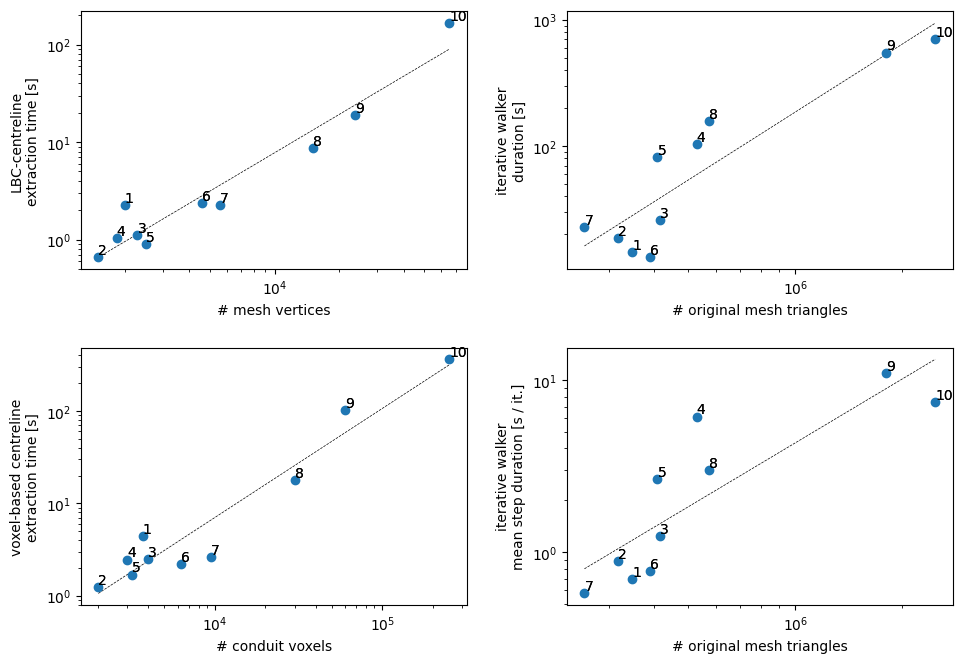

In [63]:
fig, axes = plt.subplots(2,2, figsize = (10, 7))

axes[0,0].loglog(lbc_sizes, lbc_times, "o")
ui, vi, p1 = return_powerlaw(lbc_sizes, lbc_times)
axes[0,0].plot(ui, vi, color = "k", ls = "--", zorder = -10, lw = 0.5)

axes[1,0].loglog(mst_sizes, mst_times, "o")
ui, vi, p2 = return_powerlaw(mst_sizes, mst_times)
axes[1,0].plot(ui, vi, color = "k", ls = "--", zorder = -10, lw = 0.5)

axes[0,1].loglog(iter_sizes, iter_times2, "o")
ui, vi, p3 = return_powerlaw(iter_sizes, iter_times2)
axes[0,1].plot(ui, vi, color = "k", ls = "--", zorder = -10, lw = 0.5)

axes[1,1].loglog(iter_sizes, time_per_iter, "o")
ui, vi, p4 = return_powerlaw(iter_sizes,time_per_iter)
axes[1,1].plot(ui, vi, color = "k", ls = "--", zorder = -10, lw = 0.5)


for i in range(1,11):
    axes[0, 0].text(lbc_sizes[i-1], lbc_times[i-1], i, va = "bottom")
    axes[1, 0].text(mst_sizes[i-1], mst_times[i-1], i, va = "bottom")
    axes[0,1].text(iter_sizes[i-1], iter_times2[i-1], i, va = "bottom")
    axes[1,1].text(iter_sizes[i-1], time_per_iter[i-1], i, va = "bottom")

axes[0,0].set_xlabel("# mesh vertices")
axes[0,0].set_ylabel("LBC-centreline\nextraction time [s]")

axes[1, 0].set_xlabel("# conduit voxels")
axes[1, 0].set_ylabel("voxel-based centreline\nextraction time [s]")

axes[0, 1].set_xlabel("# original mesh triangles")
axes[0, 1].set_ylabel("iterative walker\nduration [s]")

axes[1, 1].set_xlabel("# original mesh triangles")
axes[1, 1].set_ylabel("iterative walker\nmean step duration [s / it.]")

for i in range(1,11):
    axes[0, 0].text(lbc_sizes[i-1], lbc_times[i-1], i, va = "bottom")
    axes[1, 0].text(mst_sizes[i-1], mst_times[i-1], i, va = "bottom")
    axes[0,1].text(iter_sizes[i-1], iter_times2[i-1], i, va = "bottom")
    axes[1,1].text(iter_sizes[i-1], time_per_iter[i-1], i, va = "bottom")


fig.tight_layout(pad=2.0) # Adjust padding

plt.savefig("./temp/figures/summary_computation_time_needed.pdf")


In [60]:
p1, p2, p3, p4

(array([ 1.30425989, -9.96031136]),
 array([ 1.17914966, -8.91149848]),
 array([  1.79117615, -19.52043922]),
 array([  1.23800527, -15.64185841]))